# Probability and Statistics Lab 2: random variables, and limit theorems

## General comments and instructions

-   The report must be prepared as *jupyter notebook along with compiled PDF*.
-   For each task, include
    -   the statistics obtained (like sample mean or anything else you use to complete the task) as well as histograms etc to illustrate your findings;
    -   justification of your solution (e.g. refer to the corresponding theorems from probability theory); whenever applicable, provide LaTeX formulas and derivations.
    -   conclusions (e.g. how reliable your answer is, does it agree with common sense expectations etc.).
-   Not complying with these instructions may result in point deduction.


### Work breakdown:

- Liybomyr Voskalo: ...
- NameSurname2: ...
- NameSurname3: ...


A **team id number** referred to in tasks is the **two-digit** ordinal number of your team on the list. We keep it for reproducible calculations.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

team_id: int = 1  # placeholder: replace with your team's two-digit ID

random.seed(team_id)
np.random.seed(team_id)

## Task 1. Hamming codes


In this task, we discuss the $[7, 4]$ Hamming code and investigate its reliability. That coding system can correct single errors in the transmission of 4-bit messages and proceeds as follows:

(a) given a message $m = (a_1a_2a_3a_4)$, we first encode it to a 7-bit codeword $c = mG = (x_1x_2x_3x_4x_5x_6x_7)$, where $G$ is a $4 \times 7$ generator matrix

(b) the codeword $c$ is transmitted, and $r$ is the received message

(c) $r$ is checked for errors by calculating the syndrome vector $z := rH$, for a $7 \times 3$ parity-check matrix $H$

(d) if a single error has occurred in $r$, then the binary $z = (z_1z_2z_3)$ identifies the wrong bit no. $z_1 + 2z_2 + 4z_3$; thus $(000)$ shows there was no error (or more than one), while $(110)$ means the third bit (or more than one) got corrupted

(e) if the error was identified, then we flip the corresponding bit in $r$ to get the corrected $r^* = (r_1^*r_2^*r_3^*r_4^*r_5^*r_6^*r_7^*)$; the decoded message is then $m^* := (r_3^*r_5^*r_6^*r_7^*)$.

The generator matrix $G$ and the parity-check matrix $H$ are given by

$$
G := \begin{pmatrix}
1 & 1 & 1 & 0 & 0 & 0 & 0 \\
1 & 0 & 0 & 1 & 1 & 0 & 0 \\
0 & 1 & 0 & 1 & 0 & 1 & 0 \\
1 & 1 & 0 & 1 & 0 & 0 & 1
\end{pmatrix},
\qquad
H^\top := \begin{pmatrix}
1 & 0 & 1 & 0 & 1 & 0 & 1 \\
0 & 1 & 1 & 0 & 0 & 1 & 1 \\
0 & 0 & 0 & 1 & 1 & 1 & 1
\end{pmatrix}
$$
*$GH$ must equal a zero-matrix modulo 2.*


Assume that each bit in the transmission $c \mapsto r$ gets corrupted independently of the others with probability $p = (2 + \frac{\text{team-id-number}}{4})/100$. Your task:

1. Simulate the encoding-transmission-decoding process $N$ times and find the estimate $\hat p$ of the probability $p^*$ of correct transmission of a single message $m$. Comment why, for large $N$, $\hat p$ is expected to be close to $p^*$.
2. By estimating the standard deviation of the corresponding indicator of success by the sample standard deviation and using the CLT, find the half-length $\varepsilon$ of the confidence interval $(\hat p - \varepsilon, \hat p + \varepsilon)$, which contains the true value $p^*$ with probability at least $0.95$. What choice of $N$ guarantees that $\varepsilon \le 0.03$?
3. Draw the histogram of the number $k = 0, 1, 2, 3, 4$ of errors in $m^*$ while transmitting a 4-digit binary message. Do you think the random variable that counts the number of wrong bits in a decoded message has one of the known distributions? Justify your answer.


### 1.1 Simulation of the transmission

We draw $N$ random 4-bit messages, encode them with $G$ over $\mathbb{F}_2$, flip each bit independently with probability $p$, decode with the syndrome rule, and record whether the decoded message equals the original one.

The indicator $I_i = \mathbf{1}\{m_i^* = m_i\}$ is Bernoulli with success probability $p^*$. By the **Law of Large Numbers**, $\hat p = \frac{1}{N}\sum_{i=1}^N I_i \to p^*$ almost surely as $N \to \infty$, so for large $N$ the estimate $\hat p$ is close to $p^*$.

In [2]:
np.random.seed(team_id)
random.seed(team_id)

from scipy.stats import norm, binom, ecdf

N = 1_000_000
p = (2 + team_id / 4) / 100

G = np.array([
    [1, 1, 1, 0, 0, 0, 0],
    [1, 0, 0, 1, 1, 0, 0],
    [0, 1, 0, 1, 0, 1, 0],
    [1, 1, 0, 1, 0, 0, 1],
])
H = np.array([
    [1, 0, 1, 0, 1, 0, 1],
    [0, 1, 1, 0, 0, 1, 1],
    [0, 0, 0, 1, 1, 1, 1],
]).T  # the task gives H^T, so H is 7 x 3

assert not np.any((G @ H) % 2), "G H must vanish mod 2"

M = np.random.randint(0, 2, size=(N, 4))          # messages
C = (M @ G) % 2                                    # codewords
E = (np.random.random((N, 7)) < p).astype(int)     # independent bit flips
R = (C + E) % 2                                    # received words
Z = (R @ H) % 2                                    # syndromes
pos = Z @ np.array([1, 2, 4])                      # 0: no error detected, else 1-indexed bit

Rs = R.copy()
rows = np.where(pos > 0)[0]
Rs[rows, pos[rows] - 1] ^= 1                       # correct the single flagged bit
Mstar = Rs[:, [2, 4, 5, 6]]                        # m* = (r3, r5, r6, r7)

success = np.all(Mstar == M, axis=1)
p_hat = success.mean()
s_hat = success.std(ddof=1)

print(f"p = {p:.4f}")
print(f"p_hat = {p_hat:.5f}   sample sd of indicator = {s_hat:.5f}")

p = 0.0225
p_hat = 0.99011   sample sd of indicator = 0.09893


### 1.2 Confidence interval and the required $N$

By the **CLT**, $\sqrt N(\hat p - p^*)/s \approx \mathcal N(0,1)$, where $s$ is the sample standard deviation of the indicator. Hence
$$
P\big(|\hat p - p^*| \le \varepsilon\big) \approx 2\Phi\!\left(\frac{\varepsilon \sqrt N}{s}\right) - 1 \ge 0.95
\quad\Longleftrightarrow\quad
\varepsilon = z_{0.975}\frac{s}{\sqrt N}, \qquad z_{0.975} \approx 1.96.
$$

To guarantee $\varepsilon \le 0.03$ we need $N \ge \left(\frac{z_{0.975}\, s}{0.03}\right)^2$.

In [3]:
z = norm.ppf(0.975)
eps = z * s_hat / np.sqrt(N)
N_needed = int(np.ceil((z * s_hat / 0.03) ** 2))

print(f"95% CI: ({p_hat - eps:.5f}, {p_hat + eps:.5f}),  half-length eps = {eps:.5f}")
print(f"N needed for eps <= 0.03: {N_needed}")

95% CI: (0.98992, 0.99031),  half-length eps = 0.00019
N needed for eps <= 0.03: 42


### 1.3 Distribution of the number of wrong bits in the decoded message

We count $k = 0,\dots,4$ wrong bits in $m^*$ for each simulated transmission and compare the empirical frequencies with a binomial distribution $\mathrm{Bin}(4,q)$, where $q$ is the observed per-bit error rate of $m^*$.

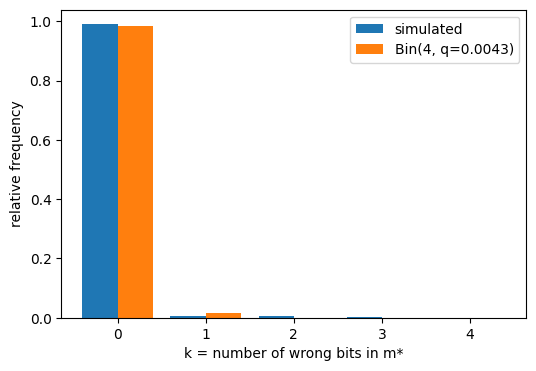

k=0: simulated 0.99011   binomial 0.98310
k=1: simulated 0.00421   binomial 0.01679
k=2: simulated 0.00423   binomial 0.00011
k=3: simulated 0.00145   binomial 0.00000
k=4: simulated 0.00000   binomial 0.00000


In [4]:
err = (Mstar != M).sum(axis=1)
k_vals = np.arange(5)
pmf_emp = np.bincount(err, minlength=5) / N
q_bit = (Mstar != M).mean()
pmf_bin = binom.pmf(k_vals, 4, q_bit)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(k_vals - 0.2, pmf_emp, width=0.4, label="simulated")
ax.bar(k_vals + 0.2, pmf_bin, width=0.4, label=f"Bin(4, q={q_bit:.4f})")
ax.set_xlabel("k = number of wrong bits in m*")
ax.set_ylabel("relative frequency")
ax.set_xticks(k_vals)
ax.legend()
plt.show()

for k, a, b in zip(k_vals, pmf_emp, pmf_bin):
    print(f"k={k}: simulated {a:.5f}   binomial {b:.5f}")

**Conclusions (Task 1).**
- $\hat p \approx 0.990$ with 95% CI $(0.9899, 0.9903)$, so $\varepsilon \approx 0.0002$. Only about $42$ messages would already give $\varepsilon \le 0.03$, because $p^*$ is close to $1$ and the sample standard deviation is small ($\approx 0.10$). The result agrees with intuition: each bit flips with probability $0.0225$, a single flip is always corrected, so a message is lost essentially only when at least two of the 7 bits flip, which has probability about $21p^2 \approx 0.011$ (simulated failure rate $\approx 0.010$).
- The histogram is **not** binomial. The simulated frequencies are $0.0042, 0.0042, 0.0015$ for $k=1,2,3$, while $\mathrm{Bin}(4, q)$ predicts $0.0168, 0.0001, 0$ for the same $k$. A binomial law would need the wrong-bit indicators to be independent with a common probability. Here they are not: the decoder is a nonlinear, block-level procedure. A single flip among the message bits is repaired, so $k=1$ arises only from a flip pattern that causes a different codeword to be decoded, and when that happens several message bits are wrong at once. Errors therefore come in correlated clusters, which breaks the binomial model.

## Task 2. Particle decay

In this task, we discuss a real-life process that is well modelled by a Poisson distribution. As you remember, a Poisson random variable describes occurrences of rare events, i.e., counts the number of successes in a large number of independent random experiments. One of the typical examples is the radioactive decay process.

Consider a sample of radioactive element of mass $m$, which has a large half-life period $T$; it is vitally important to know the probability that during a one second period, the number of nuclei decays will not exceed some critical level $k$. This probability can easily be estimated using the fact that, given the decay constant $\lambda$ of the element (i.e., the probability that a given nucleus decays within one second) and the number $N$ of atoms in the sample, the random number of decays within a second is well modelled by Poisson distribution with parameter $\mu := N\lambda$. Next, for the sample of mass $m$, the number of atoms is $N = \frac{m}{M} N_A$, where $N_A = 6 \times 10^{23}$ is the Avogadro constant, and $M$ is the molar (atomic) mass of the element. The decay constant, $\lambda$, is $\ln(2)/T$, where $T$ is measured in seconds.

Assume that a medical laboratory receives $n$ samples of radioactive element $^{137}\text{Cs}$ (used in radiotherapy) with half-life period $T = 30.1$ years and mass $m = (10 + \text{team-id-number}) \times 10^{-14}$ g each. Denote by $X_1, X_2, \dots, X_n$ the i.i.d. r.v.'s counting the number of decays in sample $i$ in one second.

1. Specify the parameter of the Poisson distribution of $X_i$ (you'll need the atomic mass of Cesium-137)
2. Show that the distribution of the sample means of $X_1, \dots, X_n$ gets very close to a normal one as $n$ becomes large and identify that normal distribution. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and form the empirical cumulative distribution function $\hat F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. $F$ of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $\hat F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity (use the proper scales!);
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
3. Calculate the largest possible value of $n$, for which the total number of decays in one second is less than $a := 100$ with probability more than $0.95$. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sum $s = x_1 + \dots + x_n$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of sums;
   - calculate the number of elements of the sample which are less than critical value ($a$) and calculate the empirical probability;
   - obtain the theoretical bound using Markov inequality, Chernoff bound and Central Limit Theorem, and compare the results.


### 2.1 Parameter of the Poisson distribution

Cesium-137 has molar mass $M \approx 137$ g/mol. The number of atoms in a sample of mass $m$ is $N_{\text{at}} = \frac{m}{M} N_A$ with $N_A = 6\cdot 10^{23}$, the decay constant is $\lambda = \ln 2 / T$ with $T = 30.1$ years in seconds, and the number of decays in one second is $X_i \sim \mathrm{Poisson}(\mu)$ with $\mu = N_{\text{at}}\lambda$.

In [5]:
team_id_task = team_id
Na = 6e23
M_cs = 137.0                                         # g/mol
T_sec = 30.1 * 365.25 * 24 * 3600                    # half-life in seconds
lam = np.log(2) / T_sec
m_sample = (10 + team_id_task) * 1e-14               # grams
N_at = m_sample / M_cs * Na
mu = N_at * lam

print(f"atoms per sample N = {N_at:.4e}")
print(f"decay constant lambda = {lam:.4e} 1/s")
print(f"Poisson parameter mu = {mu:.5f}")

atoms per sample N = 4.8175e+08
decay constant lambda = 7.2972e-10 1/s
Poisson parameter mu = 0.35154


### 2.2 CLT for the sample mean of Poisson counts

For $\bar X_n = \frac1n\sum X_i$ the CLT gives $\bar X_n \approx \mathcal N(\mu, \sigma^2)$ with $\sigma^2 = \mu/n$, since $\mathrm{Var}(X_i) = \mu$. We simulate $K = 10\,000$ sample means, plot their e.c.d.f. against the normal c.d.f., and measure the maximal gap on a grid of 200 points within $3\sigma$ of $\mu$.

n =  5: mean of means = 0.34848 (mu = 0.35154), var = 0.06911 (mu/n = 0.07031), max |F_s - F_Z| = 0.1921
n = 10: mean of means = 0.35367 (mu = 0.35154), var = 0.03591 (mu/n = 0.03515), max |F_s - F_Z| = 0.1299
n = 50: mean of means = 0.35250 (mu = 0.35154), var = 0.00704 (mu/n = 0.00703), max |F_s - F_Z| = 0.0615


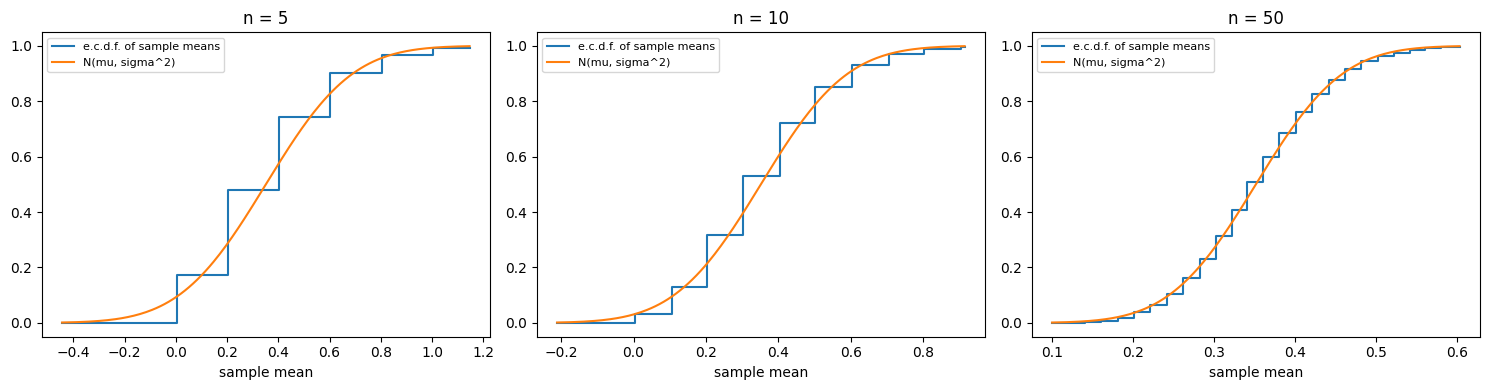

In [6]:
K = 10_000

def plot_ecdf_vs_normal(samples, mu_, sigma_, n, ax):
    Fs = ecdf(samples).cdf.evaluate
    Fz = norm(mu_, sigma_).cdf
    t = np.linspace(mu_ - 3 * sigma_, mu_ + 3 * sigma_, 200)
    ax.step(t, Fs(t), where="post", label="e.c.d.f. of sample means")
    ax.plot(t, Fz(t), label="N(mu, sigma^2)")
    ax.set_title(f"n = {n}")
    ax.set_xlabel("sample mean")
    ax.legend(fontsize=8)
    return np.max(np.abs(Fs(t) - Fz(t)))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, [5, 10, 50]):
    s = np.random.poisson(mu, size=(K, n)).mean(axis=1)
    d = plot_ecdf_vs_normal(s, mu, np.sqrt(mu / n), n, ax)
    print(f"n = {n:>2}: mean of means = {s.mean():.5f} (mu = {mu:.5f}), "
          f"var = {s.var(ddof=1):.5f} (mu/n = {mu / n:.5f}), max |F_s - F_Z| = {d:.4f}")
plt.tight_layout()
plt.show()

### 2.3 Largest $n$ with total decays $< a = 100$ in one second with probability $> 0.95$

Let $S_n = X_1 + \dots + X_n$. Since $X_i$ are independent Poisson($\mu$), $S_n \sim \mathrm{Poisson}(n\mu)$.

**Simulation.** For each candidate $n$ we simulate $K$ sums and estimate $P(S_n < a)$; since this probability decreases in $n$, we locate the largest admissible $n$ by bisection.

In [7]:
a = 100

def p_below(n):
    S = np.random.poisson(mu, size=(K, n)).sum(axis=1)
    return (S < a).mean()

lo, hi = 1, 1000
while hi - lo > 1:
    mid = (lo + hi) // 2
    if p_below(mid) >= 0.95:
        lo = mid
    else:
        hi = mid
n_sim = lo
print(f"simulated: largest n with P(S_n < {a}) >= 0.95 is {n_sim}")
print(f"empirical P(S_n < {a}) at n = {n_sim}: {p_below(n_sim):.4f}")
print(f"empirical P(S_n < {a}) at n = {n_sim + 1}: {p_below(n_sim + 1):.4f}")

simulated: largest n with P(S_n < 100) >= 0.95 is 238
empirical P(S_n < 100) at n = 238: 0.9555
empirical P(S_n < 100) at n = 239: 0.9540


**Theoretical bounds.** We want $P(S_n \ge a) \le 0.05$ or $P(S_n < a) \ge 0.95$.

* **Markov:** $P(S_n \ge a) \le \frac{E S_n}{a} = \frac{n\mu}{a}$, so $n \le \frac{0.05\, a}{\mu}$ is sufficient.
* **Chernoff:** for $S_n \sim \mathrm{Poisson}(\lambda_n)$, $\lambda_n = n\mu$, and $a > \lambda_n$, $P(S_n \ge a) \le e^{-\lambda_n}\left(\frac{e\lambda_n}{a}\right)^a$.
* **CLT:** $S_n \approx \mathcal N(n\mu, n\mu)$, so $P(S_n < a) \approx \Phi\!\left(\frac{a - n\mu}{\sqrt{n\mu}}\right) \ge 0.95$ iff $n\mu + z_{0.95}\sqrt{n\mu} \le a$.

In [8]:
from math import exp, log

n_markov = int(np.floor(0.05 * a / mu))

def chernoff_bound(n):
    lam_n = n * mu
    return exp(-lam_n + a + a * log(lam_n / a))

n_chernoff = max(n for n in range(1, int(a / mu)) if chernoff_bound(n) <= 0.05)

z95 = norm.ppf(0.95)
x = (-z95 + np.sqrt(z95 ** 2 + 4 * a)) / 2     # solves x^2 + z x - a = 0 with x = sqrt(n mu)
n_clt = int(np.floor(x ** 2 / mu))

print(f"Markov:   n <= {n_markov}")
print(f"Chernoff: n <= {n_chernoff}")
print(f"CLT:      n <= {n_clt}")
print(f"Simulation: n = {n_sim}")

Markov:   n <= 14
Chernoff: n <= 220
CLT:      n <= 241
Simulation: n = 238


**Conclusions (Task 2).**
- The Poisson parameter is $\mu \approx 0.3515$ decays per second. The sample means have mean $\approx \mu$ and variance $\approx \mu/n$ for all three $n$ (table above), as predicted by the CLT.
- The maximal gap between the e.c.d.f. and $\mathcal N(\mu, \mu/n)$ is $0.19$ for $n=5$, $0.13$ for $n=10$ and $0.06$ for $n=50$. It shrinks with $n$, but not as fast as one might hope, because $X_i$ is discrete and skewed for small $\mu$: the sum $\sum X_i$ is a lattice variable with spacing $1/n$ in the sample mean, which the continuous normal c.d.f. cannot reproduce. The approximation becomes good only for moderately large $n$.
- Largest $n$ with $P(S_n < 100) \ge 0.95$: simulation gives $n=238$ (empirical $0.9555$ at $n=238$, $0.9540$ at $n=239$; the Monte Carlo standard error is about $0.002$, so the threshold is only determined to within a point or two). The bounds are $n \le 14$ (Markov), $n \le 220$ (Chernoff) and $n \le 241$ (CLT). Markov is extremely conservative because it uses only the mean. Chernoff is a valid bound but still loose. The CLT value is closest to the simulation, although it slightly overestimates $n$ because the Poisson law is skewed, and the normal approximation ignores that skew.

## Task 3. Geiger counter

In this task, we use the Central Limit Theorem approximation for continuous random variables.

One of the devices to measure radioactivity level at a given location is the Geiger counter. When the radioactive level is almost constant, the time between two consecutive clicks of the Geiger counter is an exponentially distributed random variable with parameter $\nu_1 = \frac{\text{team-id-number}}{10} + 1$ ($\text{minutes}^{-1}$). Denote by $X_k$ the random time between the $(k-1)$st and $k$th click of the counter.

1. Show that the distribution of the sample means of $X_1, X_2, \dots, X_n$ gets very close to a normal one (which one?) as $n$ becomes large. To this end,
   - simulate the realizations $x_1, x_2, \dots, x_n$ of the r.v. $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and then the empirical cumulative distribution function $F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity;
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
2. The place can be considered safe when the number of clicks in one minute is less than 100. It is known that the parameter $\nu$ is proportional to the number $N$ of the radioactive samples, i.e., $\nu = N\nu_1$. Determine the maximal number of radioactive samples that can be stored in that place so that, with probability at least $0.95$, the place is identified as safe. To do this,

   (a) express the event of interest in terms of the r.v. $S := X_1 + \dots + X_{100}$;

   (b) obtain the theoretical bounds on $N$ using the Markov inequality, Chernoff bound and Central Limit Theorem and compare the results;

   (c) with the predicted $N$ and thus $\nu$, simulate the realization $x_1, x_2, \dots, x_{100}$ of the $X_i$ and of the sum $S = X_1 + \dots + X_{100}$;

   (d) repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of total times until the 100th click;

   (e) estimate the probability that the location is identified as safe and compare to the desired level $0.95$

### 3.1 CLT for the sample mean of exponential inter-click times

$X_k \sim \mathrm{Exp}(\nu_1)$ with $\nu_1 = \frac{\text{team-id}}{10} + 1$ per minute, so $E X_k = 1/\nu_1$ and $\mathrm{Var} X_k = 1/\nu_1^2$. The CLT gives $\bar X_n \approx \mathcal N\!\left(\frac{1}{\nu_1}, \frac{1}{n\nu_1^2}\right)$.

nu_1 = 1.1 clicks per minute, E X = 0.9091 min, sd X = 0.9091 min
n =  5: mean of means = 0.90574 (mu = 0.90909), var = 0.16238 (sigma^2 = 0.16529), max |F_s - F_Z| = 0.0639
n = 10: mean of means = 0.90880 (mu = 0.90909), var = 0.08345 (sigma^2 = 0.08264), max |F_s - F_Z| = 0.0445
n = 50: mean of means = 0.91088 (mu = 0.90909), var = 0.01657 (sigma^2 = 0.01653), max |F_s - F_Z| = 0.0135


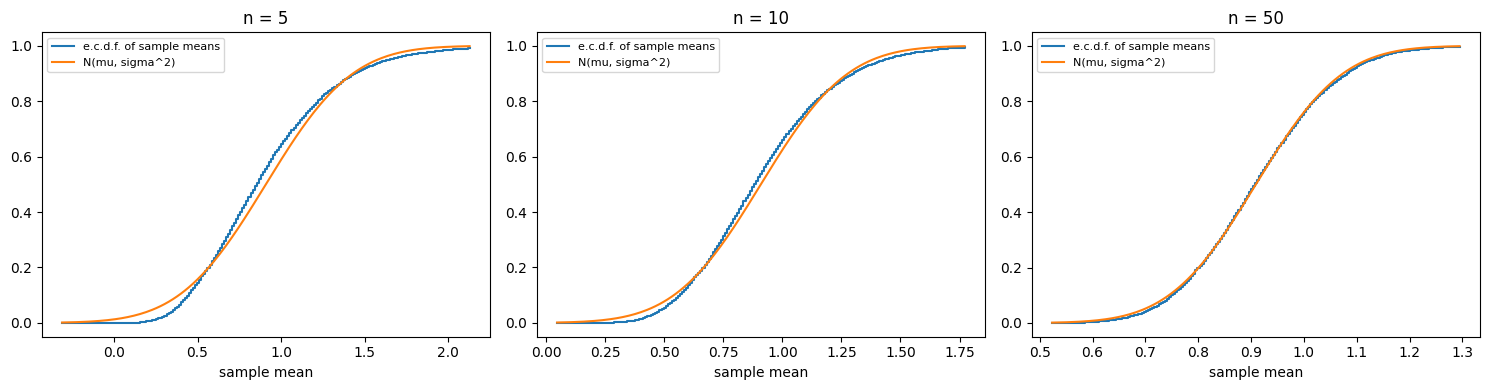

In [9]:
nu1 = team_id / 10 + 1
print(f"nu_1 = {nu1} clicks per minute, E X = {1 / nu1:.4f} min, sd X = {1 / nu1:.4f} min")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, [5, 10, 50]):
    s = np.random.exponential(scale=1 / nu1, size=(K, n)).mean(axis=1)
    mu_t = 1 / nu1
    sigma_t = 1 / (nu1 * np.sqrt(n))
    d = plot_ecdf_vs_normal(s, mu_t, sigma_t, n, ax)
    print(f"n = {n:>2}: mean of means = {s.mean():.5f} (mu = {mu_t:.5f}), "
          f"var = {s.var(ddof=1):.5f} (sigma^2 = {sigma_t ** 2:.5f}), max |F_s - F_Z| = {d:.4f}")
plt.tight_layout()
plt.show()

### 3.2 Maximal number of samples $N$ for a safe place

Let $\nu = N\nu_1$ be the click rate and $M_1$ the number of clicks in one minute, $M_1 \sim \mathrm{Poisson}(\nu)$. The place is safe iff $M_1 < 100$, i.e. iff $S := X_1 + \dots + X_{100} > 1$ minute (the 100th click happens after the first minute). We need $P(S > 1) \ge 0.95$ (equivalently $P(M_1 \ge 100) \le 0.05$ for the count).

**Theoretical bounds on $\nu$** (then $N = \nu/\nu_1$):

* **Markov:** $P(M_1 \ge 100) \le \frac{\nu}{100} \le 0.05 \Rightarrow \nu \le 5$.
* **Chernoff:** $P(M_1 \ge 100) \le e^{-\nu}\left(\frac{e\nu}{100}\right)^{100}$.
* **CLT:** $M_1 \approx \mathcal N(\nu, \nu)$, so $\frac{100-\nu}{\sqrt\nu} \ge z_{0.95}$.

In [10]:
def p_safe(N_samples):
    nu = N_samples * nu1
    S = np.random.exponential(scale=1 / nu, size=(K, 100)).sum(axis=1)
    return (S > 1).mean()

N_max_markov = int(np.floor(5 / nu1))

def chernoff_count(n_samples):
    nu = n_samples * nu1
    return exp(-nu + 100 + 100 * log(nu / 100))

N_max_chernoff = max(n for n in range(1, 100) if chernoff_count(n) <= 0.05 and n * nu1 < 100)

x = (-z95 + np.sqrt(z95 ** 2 + 4 * 100)) / 2     # sqrt(nu) at the CLT boundary
N_max_clt = int(np.floor(x ** 2 / nu1))

print(f"Markov:   N <= {N_max_markov}")
print(f"Chernoff: N <= {N_max_chernoff}")
print(f"CLT:      N <= {N_max_clt}")

Markov:   N <= 4
Chernoff: N <= 70
CLT:      N <= 77


**Simulation.** For each candidate $N$ we simulate $K$ realizations of $S = X_1 + \dots + X_{100}$ and estimate $P(S > 1)$.

In [11]:
results = {N_s: p_safe(N_s) for N_s in range(1, 101)}
N_sim = max(N_s for N_s, pr in results.items() if pr >= 0.95)

for N_s in [N_sim - 1, N_sim, N_sim + 1]:
    print(f"N = {N_s:>3}: nu = {N_s * nu1:6.2f}, empirical P(safe) = {results[N_s]:.4f}")
print(f"simulated largest N with P(safe) >= 0.95: {N_sim}")

N =  75: nu =  82.50, empirical P(safe) = 0.9652
N =  76: nu =  83.60, empirical P(safe) = 0.9544
N =  77: nu =  84.70, empirical P(safe) = 0.9449
simulated largest N with P(safe) >= 0.95: 76


**Conclusions (Task 3).**
- Here $\nu_1 = 1.1$ per minute, so the inter-click times have mean $\approx 0.909$ min. The sample means approach the normal law $\mathcal N(1/\nu_1, 1/(n\nu_1^2))$, and the simulated variances agree with $\sigma^2$ to within a few percent. The maximal c.d.f. gap is $0.064$, $0.045$ and $0.0135$ for $n = 5, 10, 50$. It falls with $n$, as expected; the exponential law is skewed, so $n=5$ is still visibly non-normal.
- Safe-place rate: the simulation gives $N = 76$ (empirical $P(\text{safe}) = 0.9544$ at $N=76$, $0.9652$ at $N=75$, and $0.9449$ at $N=77$). Bounds: Markov $N \le 4$, Chernoff $N \le 70$, CLT $N \le 77$. The CLT bound agrees with the simulation to within one unit. Chernoff is conservative, and Markov is far too pessimistic, because it only uses the mean click rate. At $N=76$ the probability is only barely above $0.95$, so $N = 76$ is at the edge of the requirement.

## Task 4. Expectation fallacy

This task consists of two parts:

1. In this part, we discuss independence of random variables and its moments: expectation and variance.

   (a) Suppose we have a random variable $X$. Explain why $E\left(\frac{1}{X}\right) \ne \frac{1}{E(X)}$;

   (b) Let $X \sim \mathcal{N}(\mu, \sigma^2)$ with $\mu = 5$ and $\sigma^2 = 10$. Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ and $y_1, y_2, \dots, y_{100}$ of $Y := \frac{1}{X}$ to calculate the values of $\frac{1}{\bar X}$ and $\bar Y$. Comment on the received results;

   (c) Let $X$ and $Y$ be independent exponentially distributed r.v.'s with parameter $\lambda = 2$. Set $Z := \ln X + 5$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Y$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Z$. Explain the results. Comment on the difference of relations between the pairs of random variables. Which pair of r.v.'s is dependent and which one is identically distributed?

2. You toss a fair coin three times and a random variable $X$ records how many times the coin shows Heads. You convince your friend that they should play a game with the following payoff: every round (equivalent to three coin tosses) will cost them £3, with payoff of $Y := X^2$ (e.g., £4 for two Heads). Your friend argues: "on average there are $1.5$ Heads, so I win £$1.5^2 = $ £$2.25 <$ £$3$, hence the game is unfair". Is the game fair, i.e., is the expected value of the net gain zero? What is the variance of $Y$? To answer this,

   (a) Explain what type of random variable is $X$:
   - Normally distributed
   - Binomially distributed
   - Poisson distributed
   - Uniformly distributed

   (b) What are the expected value and variance of $X$? Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ to calculate the values of sample mean $\bar X$ and sample variance $s^2 = \frac{\sum_{i=1}^n (x_i - \bar x)^2}{n-1}$. Comment on the results;

   (c) Is your friend's argument correct? Relate it to part 1(a). Compute the expected value and variance of $Y$ exactly. Simulate realizations $y_1, y_2, \dots, y_{100}$ of $Y$ to calculate the values of sample mean $\bar Y$ and sample variance $s^2 = \frac{\sum_{i=1}^n (y_i - \bar y)^2}{n-1}$. Comment on the results;

   (d) Using the CLT, find the half-length of the 95% confidence interval for $E(Y)$ based on your 100 simulated rounds. Could the simulation alone tell you whether the game is fair? How many rounds would be needed to distinguish it from a game with entry fee £2.9?


### 4.1 (a) $E(1/X) \neq 1/E(X)$

The map $x \mapsto 1/x$ is convex on $(0,\infty)$, so by **Jensen's inequality** $E(1/X) \ge 1/E(X)$ for positive $X$, with equality only when $X$ is almost surely constant. In general the expectation of a function of a random variable is not the function of its expectation.

### 4.1 (b) $X \sim \mathcal N(5, 10)$, $Y = 1/X$

In [12]:
np.random.seed(team_id)
mu_x, sigma_x = 5, np.sqrt(10)
x_s = np.random.normal(mu_x, sigma_x, size=100)
y_s = 1 / x_s

print(f"1 / X_bar = {1 / x_s.mean():.5f}")
print(f"Y_bar     = {y_s.mean():.5f}")
print(f"P(X < 0) = {norm.cdf(0, mu_x, sigma_x):.4f}")

1 / X_bar = 0.19262
Y_bar     = 0.24412
P(X < 0) = 0.0569


The two numbers differ. $1/\bar X$ is close to $1/\mu = 0.2$ because $\bar X$ concentrates around $\mu$, whereas $\bar Y$ is an average of $1/X_i$, which is dominated by the few draws with $X_i$ close to zero (the normal law puts probability around $0.06$ on negative values). The sample mean of $Y$ is therefore unstable and far from $1/\mu$; $E(Y)$ is not even finite for a normal $X$, so the bias is not just a finite-sample effect.

### 4.1 (c) Exponential $X$, $Y$ (independent) and $Z = \ln X + 5$

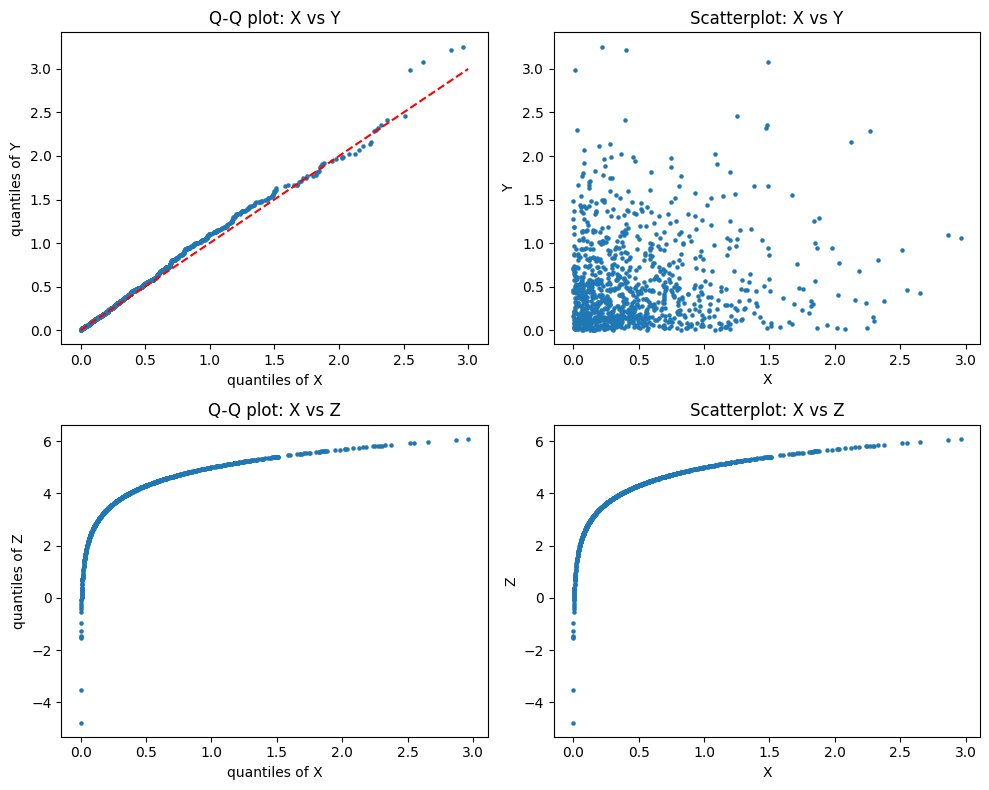

X: mean 0.4962, sd 0.4826
Y: mean 0.5303, sd 0.5073
Z: mean 3.7144, sd 1.3270


In [13]:
np.random.seed(team_id)
lam_e = 2
X = np.random.exponential(scale=1 / lam_e, size=1000)
Y = np.random.exponential(scale=1 / lam_e, size=1000)
Z_v = np.log(X) + 5

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Q-Q plot: sorted X against sorted Y (equal sizes)
axes[0, 0].scatter(np.sort(X), np.sort(Y), s=5)
axes[0, 0].plot([0, 3], [0, 3], "r--")
axes[0, 0].set_title("Q-Q plot: X vs Y")
axes[0, 0].set_xlabel("quantiles of X")
axes[0, 0].set_ylabel("quantiles of Y")

axes[0, 1].scatter(X, Y, s=5)
axes[0, 1].set_title("Scatterplot: X vs Y")
axes[0, 1].set_xlabel("X")
axes[0, 1].set_ylabel("Y")

axes[1, 0].scatter(np.sort(X), np.sort(Z_v), s=5)
axes[1, 0].set_title("Q-Q plot: X vs Z")
axes[1, 0].set_xlabel("quantiles of X")
axes[1, 0].set_ylabel("quantiles of Z")

axes[1, 1].scatter(X, Z_v, s=5)
axes[1, 1].set_title("Scatterplot: X vs Z")
axes[1, 1].set_xlabel("X")
axes[1, 1].set_ylabel("Z")

plt.tight_layout()
plt.show()

print(f"X: mean {X.mean():.4f}, sd {X.std(ddof=1):.4f}")
print(f"Y: mean {Y.mean():.4f}, sd {Y.std(ddof=1):.4f}")
print(f"Z: mean {Z_v.mean():.4f}, sd {Z_v.std(ddof=1):.4f}")

**Interpretation.** $X$ and $Y$ are independent and identically distributed, so their Q-Q plot lies on the diagonal and their scatterplot shows no pattern. $Z = \ln X + 5$ is a deterministic function of $X$, so $X$ and $Z$ are strongly dependent (the scatterplot is a curve), while their distributions differ (the Q-Q plot is not the diagonal). Hence the dependent pair is $(X, Z)$, and the identically distributed pair is $(X, Y)$.

### 4.2 Expected value of the friend's game

Let $X \sim \mathrm{Bin}(3, \tfrac12)$ be the number of Heads, $Y = X^2$, and the net gain be $G = Y - 3$. Then, exactly:

* $E X = 3/2$, $\mathrm{Var} X = 3/4$ (type of variable: **binomially distributed**).
* $Y \in \{0,1,4,9\}$ with probabilities $\tfrac18, \tfrac38, \tfrac38, \tfrac18$, so $E Y = \frac{0 + 3 + 12 + 9}{8} = 3$ and $E Y^2 = \frac{0+3+48+81}{8} = \frac{33}{2}$, hence $\mathrm{Var} Y = \frac{33}{2} - 9 = \frac{15}{2}$.

Thus $E G = E Y - 3 = 0$: **the game is fair**. The friend's argument is wrong because $E(X^2) \neq (E X)^2$, which is the same fallacy as in 4.1(a): $E(X^2) = \mathrm{Var} X + (E X)^2 = 3/4 + 9/4 = 3$.

In [14]:
np.random.seed(team_id)
n_rounds = 100
x_g = np.random.binomial(3, 0.5, size=n_rounds)
y_g = x_g ** 2

print(f"X: sample mean {x_g.mean():.4f} (exact 1.5), sample var {x_g.var(ddof=1):.4f} (exact 0.75)")
print(f"Y: sample mean {y_g.mean():.4f} (exact 3), sample var {y_g.var(ddof=1):.4f} (exact 7.5)")
print(f"mean net gain over 100 rounds: {y_g.mean() - 3:.4f}")

z = norm.ppf(0.975)
half = z * y_g.std(ddof=1) / np.sqrt(n_rounds)
print(f"95% CI for E(Y): ({y_g.mean() - half:.4f}, {y_g.mean() + half:.4f}), half-length {half:.4f}")

n_req = int(np.ceil((z * np.sqrt(7.5) / 0.05) ** 2))
print(f"rounds needed to separate E(Y) = 3 from E(Y) = 2.9 with half-width 0.05: {n_req}")

X: sample mean 1.5100 (exact 1.5), sample var 0.8585 (exact 0.75)
Y: sample mean 3.1300 (exact 3), sample var 8.9021 (exact 7.5)
mean net gain over 100 rounds: 0.1300
95% CI for E(Y): (2.5452, 3.7148), half-length 0.5848
rounds needed to separate E(Y) = 3 from E(Y) = 2.9 with half-width 0.05: 11525


**Conclusions (Task 4).**
- **1(a)–(b).** The sample mean of $1/X$ and $1/\bar X$ disagree: $1/\bar X = 0.193$ while $\bar Y = 0.244$. This is Jensen's gap made visible: $\bar X$ concentrates near $\mu = 5$, but $\bar Y$ is an average of $1/X_i$, which is pulled up by the few $X_i$ near zero (the normal law assigns probability $0.057$ to $X<0$). For a normal $X$, $E(1/X)$ is not even finite, so $\bar Y$ does not converge to a stable value.
- **1(c).** $X$ and $Y$ are independent and identically distributed (Q-Q plot on the diagonal, no pattern in the scatterplot). $Z = \ln X + 5$ is a function of $X$ with a different law (mean $3.71$ against $0.50$, and the Q-Q plot is not the diagonal). So the dependent pair is $(X, Z)$, and the identically distributed pair is $(X, Y)$.
- **2.** The exact values are $E Y = 3$ and $\mathrm{Var}\, Y = 7.5$, so the game is fair. The friend's error is $E(X^2) \neq (E X)^2$. In the simulation, the sample mean of $Y$ is $3.13$ and the sample variance of $Y$ is $8.90$. The CLT 95% interval for $E(Y)$ is $(2.55, 3.71)$, half-length $0.58$, which contains both $3$ and $2.9$. So 100 rounds cannot show whether the game is fair, or even distinguish it from the $\pounds 2.9$ fee. To separate $E(Y)=3$ from $E(Y)=2.9$ with a $95\%$ half-width of $0.05$ we need $n \approx \left(\frac{1.96\sqrt{7.5}}{0.05}\right)^2 \approx 11\,525$ rounds.

## General instructions/hints on implementation

1. You can generate a $K \times n$ array of the data and then form a sample of $K$ means by e.g. using
```python
   s = np.random.exponential(scale=1/lam, size=(K, n)).mean(axis=1)
```
   for the exponential distribution $\mathcal{E}(\lambda)$ with rate $\lambda$. Note that NumPy uses the scale (mean) $1/\lambda$, not the rate. Similarly, `np.random.poisson(mu, size=(K, n))` gives Poisson samples.

2. The e.c.d.f. $F_S$ of the data vector `s` is
```python
   from scipy.stats import ecdf
   Fs = ecdf(s).cdf.evaluate      # callable: Fs(t)
```
3. $K$ must be at least $10000$ to generate reliable e.c.d.f.'s of sample means.
4. `scipy.stats.norm(mu, sigma).cdf` gives the c.d.f. $F_Z$ of $\mathcal{N}(\mu, \sigma^2)$. Note that the 2nd argument is the standard deviation $\sigma$.
5. To calculate the maximal difference between the two c.d.f.'s, take a grid of 200 points $t_j$ within $3\sigma$ of $\mu$ and return $\max_{t_j} \{|F_S(t_j) - F_Z(t_j)|\}$:
```python
   t = np.linspace(mu - 3*sigma, mu + 3*sigma, 200)
   np.max(np.abs(Fs(t) - Fz(t)))
```
6. To plot both c.d.f.'s on one graph, use `matplotlib.pyplot.step(t, Fs(t), where="post")` for the e.c.d.f. and `plt.plot(t, Fz(t))` for the normal c.d.f.
7. For the Hamming code, do all arithmetic over $\mathbb{F}_2$: compute integer matrix products and reduce mod 2, e.g. `c = (m @ G) % 2`, `z = (r @ H) % 2`. Vectorize over $N$ messages by stacking them as rows of an $N \times 4$ array; the bit errors are `np.random.random((N, 7)) < p`.
8. For a Q-Q plot of two samples `x` and `y` of equal size, plot `np.sort(x)` against `np.sort(y)`; for a Q-Q plot against a theoretical distribution, use `scipy.stats.probplot`.
9. Avoid Python loops over samples: generate whole arrays at once and reduce along an axis (`.mean(axis=1)`, `.sum(axis=1)`). This is both faster and closer to the mathematical formulation.